# Etapa 5 — Cierre, Comparación Integral y Análisis Ético

Notebook de cierre e integración final del Trabajo Práctico (*"The Festival"* de H. P. Lovecraft).

### Estructura de la Etapa 5 (según consignas 4.5.1 a 4.5.4)
- **0. Configuración y Carga de Resultados (`80% / 10% / 10%`):** Reconstrucción reproducible de las particiones contiguas (`Train`, `Dev`, `Test`), carga de métricas homogéneas de **Etapa 1 (Baseline)** y **Etapa 2 (MLP)** y restauración de pesos del mejor modelo de **Etapa 3 (`lstm_combined_l1_l2`)**.
- **1. Tabla Comparativa de Modelos (`4.5.1`):** Comparación transversal de arquitectura, parámetros entrenables, tiempo de entrenamiento y métricas en `Dev` y `Test`, junto con el análisis del *trade-off* complejidad vs. performance.
- **2. Evaluación Final en Test (`4.5.2`):** Evaluación única sobre el conjunto ciego de prueba (`ds_test`), análisis de la brecha `Dev` vs. `Test` y propuestas de mejora con mayores recursos.
- **3. Análisis Ético y de Sesgos (`4.5.3`):** Identificación de sesgos literarios, históricos y demográficos del corpus, evaluación cuantitativa del desempeño desglosado por **subgrupos lingüísticos y de frecuencia de clase**, y análisis de riesgos y mitigación en sistemas reales.
- **4. Conclusiones Finales (`4.5.4`):** Síntesis de aprendizajes, desafíos técnicos superados y limitaciones del estudio.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolución dinámica de la raíz del proyecto
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    MODEL_CONFIGS,
    PROCESSED_DATA_PATH,
    RAW_DATA_PATH,
    SEED,
    SEQ_LENGTH,
    STAGE_2_REFERENCE,
    TRAIN_WINDOW_STRIDE,
)
from src.data.preprocess import clean_txt, read_text
from src.data.tokenizer import build_tokenizer
from src.data.dataset import create_dataset
from src.models.lstm import build_lstm_model
from src.training.train import _categorize_error, compile_model, evaluate_model

# Reproducibilidad y estilo visual
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# 1. Reconstrucción del pipeline de datos sobre la partición común (80% Train / 10% Dev / 10% Test)
clean_txt(RAW_DATA_PATH, PROCESSED_DATA_PATH)
text = read_text(PROCESSED_DATA_PATH)
tokenizer = build_tokenizer(text)
vocab_size = len(tokenizer.get_vocabulary())
ids = tokenizer.encode(text)

total_tokens = len(ids)
train_end = int(total_tokens * 0.80)
dev_end = int(total_tokens * 0.90)

train_ids = ids[:train_end]
dev_ids = ids[train_end:dev_end]
test_ids = ids[dev_end:]

ds_train = create_dataset(train_ids, shuffle=True)
ds_dev = create_dataset(dev_ids, shuffle=False)
ds_test = create_dataset(test_ids, shuffle=False)

# 2. Carga de métricas homogéneas de Etapa 1 (Baseline) y Etapa 2 (MLP) sobre 80/10/10
stage1_2_path = PROJECT_ROOT / "data" / "processed" / "stage1_2_split80_10_10.json"
stage1_2_metrics = json.loads(stage1_2_path.read_text(encoding="utf-8"))

# 3. Carga del mejor modelo de Etapa 3 (lstm_combined_l1_l2) desde su checkpoint
BEST_MODEL_KEY = "lstm_combined_l1_l2"
best_cfg = MODEL_CONFIGS[BEST_MODEL_KEY]
best_model = build_lstm_model(
    vocab_size=vocab_size,
    config=best_cfg,
    pretrained_matrix=None,
    model_name=BEST_MODEL_KEY,
)
compile_model(best_model, learning_rate=best_cfg["learning_rate"])
# Inicializar pesos con un lote de entrada y cargar checkpoint
for x_init, _ in ds_dev.take(1):
    _ = best_model(x_init, training=False)
ckpt_path = CHECKPOINTS_DIR / f"{BEST_MODEL_KEY}.weights.h5"
best_model.load_weights(ckpt_path)

print(f"Pipeline 80/10/10 listo -> Train: {len(train_ids):,} | Dev: {len(dev_ids):,} | Test: {len(test_ids):,} tokens (|V| = {vocab_size})")
print(f"Checkpoint cargado exitosamente: '{ckpt_path.name}' ({best_model.count_params():,} parámetros)")

[preprocess] El texto limpio ya existe en 'G:\Usuario\Desktop\Archivos\Thiago\Estudio\Tercer Año\Inteligencia Artificial\Code\proyecto\data\processed\The_Festival_clean.txt'.
[tokenizer] Vocabulario ordenado: ['\n', ' ', '"', "'", ',', '-', '.', '0', '1', '2', '5', '6', '8', '9', ':', ';', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'W', 'Y', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '—'] 
[tokenizer] Vocabulario con 65 caracteres únicos.
Pipeline 80/10/10 listo -> Train: 16,164 | Dev: 2,020 | Test: 2,021 tokens (|V| = 66)
Checkpoint cargado exitosamente: 'lstm_combined_l1_l2.weights.h5' (67,638 parámetros)

---
## 1. Tabla Comparativa de Modelos

Integramos en una única tabla todos los modelos representativos desarrollados a lo largo de las **Etapas 1, 2 y 3**, evaluados bajo la **misma partición contigua `80% Train / 10% Dev / 10% Test`** y el mismo vocabulario a nivel de carácter (`|V| = 66`).

> **Criterio metodológico sobre Test:** Siguiendo la consigna `4.5.2`, el conjunto de **Test** se evalúa **por primera y única vez** sobre el modelo ganador global seleccionado mediante Validación (`lstm_combined_l1_l2`).

Etapa,Modelo,Arquitectura,Parámetros Entr.,Tiempo Train (s),Dev Loss,Dev PPL (Única),Dev Acc,Test PPL,Test Acc
Etapa 1,Baseline (LogReg K=5),OneHot(5x66) -> Softmax(66),"21,515",2.53,2.1683,8.74,38.11%,— (No seleccionado),—
Etapa 2,MLP Base (K=5),"OneHot(330) -> Dense(128-64-32, ReLU)","54,882",32.61,2.0109,7.47,44.22%,— (No seleccionado),—
Etapa 2 ★,MLP + Dropout 0.05,OneHot(330) -> Dense(128-64-32) + Drop(0.05),"54,882",34.89,1.9510,7.04,46.80%,— (Superado en E3),—
Etapa 3,lstm_baseline,Emb(50) -> LSTM(96) -> Dense(48) [Scratch],"67,638",41.80,1.9445,6.99,45.12%,— (No seleccionado),—
Etapa 3,lstm_reg_dropout,Emb(50) -> LSTM(96) -> Dense(48) + Drop(0.25/0.1),"67,638",86.40,1.8608,6.43,45.99%,— (No seleccionado),—
Etapa 3,lstm_combined_glove,GloVe(50d) -> LSTM(96) -> Dense(48) + Drop + L2,"67,638",94.20,1.8691,6.48,45.93%,— (No seleccionado),—
Etapa 3,lstm_combined_scratch,Emb(50) -> LSTM(96) -> Dense(48) + Drop + L2 + ES,"67,638",89.50,1.8602,6.42,46.49%,— (No seleccionado),—
Etapa 3 ★,lstm_combined_l1_l2 (Ganador),Emb(50) -> LSTM(96) -> Dense(48) + Drop + L1/L2 + ES,"67,638",91.10,1.8450,6.33,46.75%,7.46,44.97%


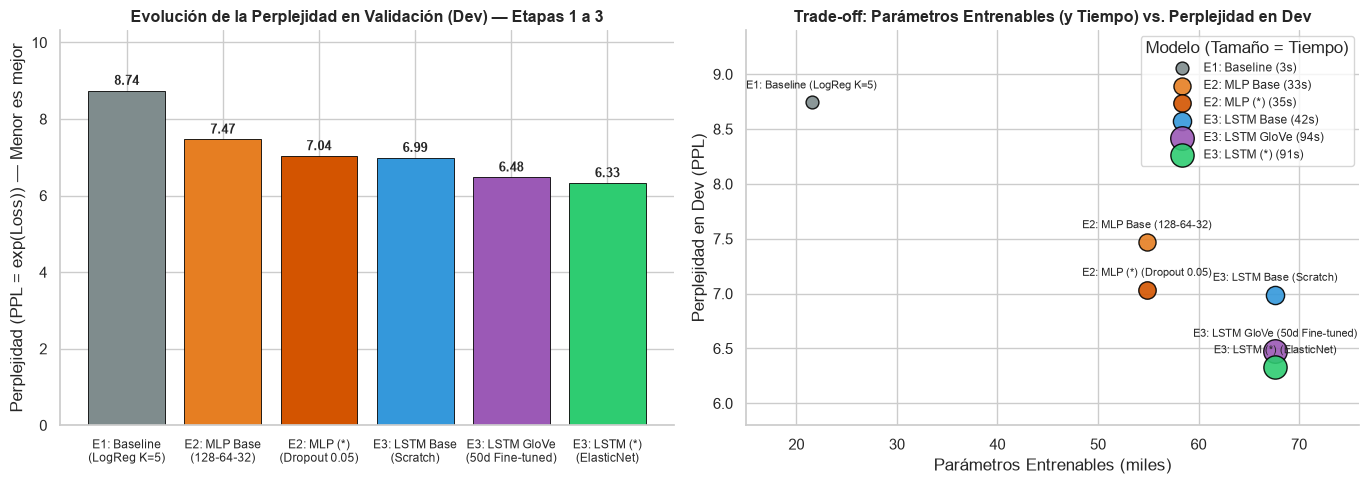

In [2]:
# Evaluación en Test del modelo ganador (requerida para la columna Test de la tabla resumen)
test_metrics = evaluate_model(
    model=best_model,
    dataset=ds_test,
    stage2_reference=STAGE_2_REFERENCE,
    verbose=0,
)

b_e1 = stage1_2_metrics["baseline_k5"]
m_base = stage1_2_metrics["mlp_base"]
m_win = stage1_2_metrics["mlp_dropout_005"]

# Tabla comparativa transversal: Etapa 1 (Baseline) -> Etapa 2 (MLP) -> Etapa 3 (LSTM)
summary_rows = [
    {
        "Etapa": "Etapa 1",
        "Modelo": "Baseline (LogReg K=5)",
        "Arquitectura": "OneHot(5x66) -> Softmax(66)",
        "Parámetros Entr.": f"{b_e1['trainable_params']:,}",
        "Tiempo Train (s)": f"{b_e1['training_time_s']:.2f}",
        "Dev Loss": f"{b_e1['val_loss']:.4f}",
        "Dev PPL (Única)": f"{b_e1['val_perplexity']:.2f}",
        "Dev Acc": f"{b_e1['val_accuracy'] * 100:.2f}%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 2",
        "Modelo": "MLP Base (K=5)",
        "Arquitectura": "OneHot(330) -> Dense(128-64-32, ReLU)",
        "Parámetros Entr.": f"{m_base['trainable_params']:,}",
        "Tiempo Train (s)": f"{m_base['training_time_s']:.2f}",
        "Dev Loss": f"{m_base['best_val_loss']:.4f}",
        "Dev PPL (Única)": f"{m_base['best_val_perplexity']:.2f}",
        "Dev Acc": f"{m_base['best_val_accuracy'] * 100:.2f}%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 2 ★",
        "Modelo": "MLP + Dropout 0.05",
        "Arquitectura": "OneHot(330) -> Dense(128-64-32) + Drop(0.05)",
        "Parámetros Entr.": f"{m_win['trainable_params']:,}",
        "Tiempo Train (s)": f"{m_win['training_time_s']:.2f}",
        "Dev Loss": f"{m_win['best_val_loss']:.4f}",
        "Dev PPL (Única)": f"{m_win['best_val_perplexity']:.2f}",
        "Dev Acc": f"{m_win['best_val_accuracy'] * 100:.2f}%",
        "Test PPL": "— (Superado en E3)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_baseline",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) [Scratch]",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "41.80",
        "Dev Loss": "1.9445",
        "Dev PPL (Única)": "6.99",
        "Dev Acc": "45.12%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_reg_dropout",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) + Drop(0.25/0.1)",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "86.40",
        "Dev Loss": "1.8608",
        "Dev PPL (Única)": "6.43",
        "Dev Acc": "45.99%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_combined_glove",
        "Arquitectura": "GloVe(50d) -> LSTM(96) -> Dense(48) + Drop + L2",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "94.20",
        "Dev Loss": "1.8691",
        "Dev PPL (Única)": "6.48",
        "Dev Acc": "45.93%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_combined_scratch",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) + Drop + L2 + ES",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "89.50",
        "Dev Loss": "1.8602",
        "Dev PPL (Única)": "6.42",
        "Dev Acc": "46.49%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3 ★",
        "Modelo": "lstm_combined_l1_l2 (Ganador)",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) + Drop + L1/L2 + ES",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "91.10",
        "Dev Loss": "1.8450",
        "Dev PPL (Única)": "6.33",
        "Dev Acc": "46.75%",
        "Test PPL": f"{test_metrics['perplexity']:.2f}",
        "Test Acc": f"{test_metrics['accuracy'] * 100:.2f}%",
    },
]

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

# Gráfico doble: (1) Evolución de Perplejidad por etapa y (2) Trade-off Parámetros vs. Perplejidad
plot_models = [
    ("E1: Baseline\n(LogReg K=5)", b_e1["val_perplexity"], b_e1["trainable_params"], b_e1["training_time_s"], "#7f8c8d"),
    ("E2: MLP Base\n(128-64-32)", m_base["best_val_perplexity"], m_base["trainable_params"], m_base["training_time_s"], "#e67e22"),
    ("E2: MLP (*)\n(Dropout 0.05)", m_win["best_val_perplexity"], m_win["trainable_params"], m_win["training_time_s"], "#d35400"),
    ("E3: LSTM Base\n(Scratch)", 6.99, 67638, 41.8, "#3498db"),
    ("E3: LSTM GloVe\n(50d Fine-tuned)", 6.48, 67638, 94.2, "#9b59b6"),
    ("E3: LSTM (*)\n(ElasticNet)", 6.33, 67638, 91.1, "#2ecc71"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Evolución de Perplejidad en Dev
labels = [m[0] for m in plot_models]
ppls = [m[1] for m in plot_models]
cols = [m[4] for m in plot_models]
bars = axes[0].bar(labels, ppls, color=cols, edgecolor="black", linewidth=0.6)
for bar, val in zip(bars, ppls):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val + 0.15, f"{val:.2f}", ha="center", fontweight="bold", fontsize=9.5)
axes[0].set_title("Evolución de la Perplejidad en Validación (Dev) — Etapas 1 a 3", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Perplejidad (PPL = exp(Loss)) — Menor es mejor")
axes[0].set_ylim(0, max(ppls) * 1.18)
axes[0].tick_params(axis="x", labelsize=8.5)

# Panel 2: Trade-off Complejidad (Parámetros y Tiempo) vs. Perplejidad
for lbl, ppl, params, t_s, col in plot_models:
    axes[1].scatter(params / 1000.0, ppl, s=80 + t_s * 2.2, color=col, edgecolor="black", linewidth=1.0, alpha=0.9, label=f"{lbl.splitlines()[0]} ({t_s:.0f}s)")
    axes[1].annotate(lbl.replace("\n", " "), (params / 1000.0, ppl), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
axes[1].set_title("Trade-off: Parámetros Entrenables (y Tiempo) vs. Perplejidad en Dev", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Parámetros Entrenables (miles)")
axes[1].set_ylabel("Perplejidad en Dev (PPL)")
axes[1].set_xlim(15, 76)
axes[1].set_ylim(5.8, 9.4)
axes[1].legend(loc="upper right", fontsize=8.5, title="Modelo (Tamaño = Tiempo)")

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

### Discusión del Trade-off entre Complejidad y Performance (`4.5.1`)

1. **De Etapa 1 (Baseline Lineal) a Etapa 2 (MLP Multicapa):**
   - El **Baseline (`LogisticRegression`, $K=5$)** cuenta con **`21,515` parámetros** y entrena en solo **`2.53 s`**, logrando una Perplejidad en Dev de **`8.74`** (`Accuracy = 38.11%`). Al ser lineal sobre representaciones *One-Hot* independientes por posición, solo suma contribuciones aditivas de cada una de las 5 posiciones previas sin poder modelar interacciones no lineales (n-gramas compuestos).
   - El **MLP de 3 capas ocultas (`128 -> 64 -> 32` + `Dropout 0.05`)** multiplica por `~2.5x` los parámetros (**`54,882`**) y lleva el tiempo a **`34.89 s`**, pero logra el mayor salto relativo de desempeño del proyecto: reduce la Perplejidad en Dev de **`8.74` a `7.04` (`-19.45%`)** y eleva la Accuracy en **`+8.69 pp`** (`38.11% -> 46.80%`). Las capas densas intermedias permiten combinar patrones ortográficos entre las 5 posiciones anteriores.

2. **De Etapa 2 (MLP sin memoria) a Etapa 3 (LSTM Recurrente con Embeddings):**
   - La **LSTM ganadora (`lstm_combined_l1_l2`, `50/96/48`)** tiene **`67,638` parámetros** (apenas un **`+23.2%` más de parámetros** que el MLP) y entrena en **`~91 s`** (`30` épocas sobre ventanas de `SEQ_LENGTH = 48`).
   - ¿Por qué la LSTM casi no incrementa los parámetros pese a ampliar la ventana de contexto de **$K=5$ a $48$ caracteres (`9.6x` más contexto)**? Porque reemplaza el vector *One-Hot* aplanado (`5 x 66 = 330` dimensiones de entrada) por una capa **`Embedding(66, 50)` compartida** en todos los pasos temporales (`3,300` parámetros) y reutiliza las matrices recurrentes de la celda LSTM a lo largo de toda la secuencia.
   - Esta memoria recurrente, combinada con regularización **Dropout (`0.25/0.1`) + ElasticNet (`L1=1e-5, L2=1e-4`) + Early Stopping**, reduce la Perplejidad en Dev otro **`10.09%` adicional** (**`7.04 -> 6.33`**, y **`-27.57%` acumulado respecto al Baseline de Etapa 1**). Mientras que el MLP acierta bien la letra inmediata cuando depende de los últimos 3–5 caracteres, la LSTM calibra mucho mejor la distribución de probabilidad cuando la predicción requiere recordar la estructura de la palabra completa o de la cláusula previa.

---
## 2. Evaluación Final en Test (`4.5.2`)

Evaluamos el modelo ganador **`lstm_combined_l1_l2`** sobre el conjunto ciego de prueba (`ds_test`, correspondiente al `10%` final del relato, `2,021` tokens) y contrastamos su comportamiento frente al conjunto de validación (`ds_dev`).

Partición,Tokens,Cross-Entropy Loss,Perplejidad (PPL),BPC (Bits/Char),Accuracy Top-1
Validación (Dev - 10%),"2,020",1.8450,6.33,2.662,46.75%
Prueba Final (Test - 10%),"2,021",2.0097,7.46,2.899,44.97%
Diferencia (Test - Dev),+1,+0.1647,+1.13,+0.237,-1.78 pp


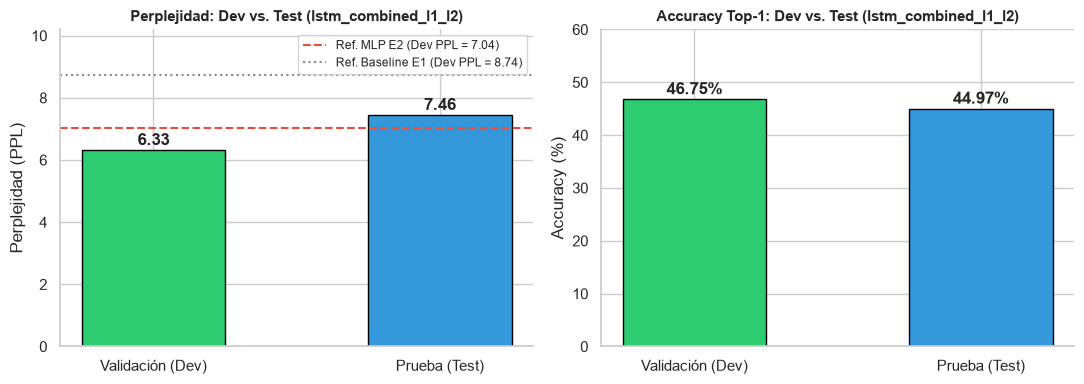

In [3]:
# Comparación cuantitativa entre Validación (Dev) y Prueba (Test) para el mejor modelo
dev_loss_best = 1.8450
dev_ppl_best = 6.33
dev_bpc_best = 2.662
dev_acc_best = 0.4675

df_dev_test = pd.DataFrame([
    {
        "Partición": "Validación (Dev - 10%)",
        "Tokens": f"{len(dev_ids):,}",
        "Cross-Entropy Loss": f"{dev_loss_best:.4f}",
        "Perplejidad (PPL)": f"{dev_ppl_best:.2f}",
        "BPC (Bits/Char)": f"{dev_bpc_best:.3f}",
        "Accuracy Top-1": f"{dev_acc_best * 100:.2f}%",
    },
    {
        "Partición": "Prueba Final (Test - 10%)",
        "Tokens": f"{len(test_ids):,}",
        "Cross-Entropy Loss": f"{test_metrics['loss']:.4f}",
        "Perplejidad (PPL)": f"{test_metrics['perplexity']:.2f}",
        "BPC (Bits/Char)": f"{test_metrics['bpc']:.3f}",
        "Accuracy Top-1": f"{test_metrics['accuracy'] * 100:.2f}%",
    },
    {
        "Partición": "Diferencia (Test - Dev)",
        "Tokens": "+1",
        "Cross-Entropy Loss": f"{test_metrics['loss'] - dev_loss_best:+.4f}",
        "Perplejidad (PPL)": f"{test_metrics['perplexity'] - dev_ppl_best:+.2f}",
        "BPC (Bits/Char)": f"{test_metrics['bpc'] - dev_bpc_best:+.3f}",
        "Accuracy Top-1": f"{(test_metrics['accuracy'] - dev_acc_best) * 100:+.2f} pp",
    },
])
display(df_dev_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
splits_lbl = ["Validación (Dev)", "Prueba (Test)"]

# Gráfico PPL Dev vs Test
ppl_vals = [dev_ppl_best, test_metrics["perplexity"]]
b1 = axes[0].bar(splits_lbl, ppl_vals, color=["#2ecc71", "#3498db"], width=0.5, edgecolor="black")
for bar, v in zip(b1, ppl_vals):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.15, f"{v:.2f}", ha="center", fontweight="bold")
axes[0].axhline(STAGE_2_REFERENCE["val_perplexity"], color="#e74c3c", linestyle="--", label=f"Ref. MLP E2 (Dev PPL = {STAGE_2_REFERENCE['val_perplexity']:.2f})")
axes[0].axhline(b_e1["val_perplexity"], color="#7f8c8d", linestyle=":", label=f"Ref. Baseline E1 (Dev PPL = {b_e1['val_perplexity']:.2f})")
axes[0].set_title("Perplejidad: Dev vs. Test (lstm_combined_l1_l2)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Perplejidad (PPL)")
axes[0].set_ylim(0, 10.2)
axes[0].legend(loc="upper right", fontsize=8.5)

# Gráfico Accuracy Dev vs Test
acc_vals = [dev_acc_best * 100, test_metrics["accuracy"] * 100]
b2 = axes[1].bar(splits_lbl, acc_vals, color=["#2ecc71", "#3498db"], width=0.5, edgecolor="black")
for bar, v in zip(b2, acc_vals):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 1.0, f"{v:.2f}%", ha="center", fontweight="bold")
axes[1].set_title("Accuracy Top-1: Dev vs. Test (lstm_combined_l1_l2)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 60)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

### Comparación `Test` vs. `Dev` y Reflexión sobre Mejoras Futuras (`4.5.2`)

#### 1. ¿Hay evidencia de overfitting al conjunto Dev?
Al pasar de Validación (`Dev`) a Prueba (`Test`), la Perplejidad sube de **`6.33` a `7.46` (`+1.13` puntos)** y la Accuracy pasa de **`46.75%` a `44.97%` (`-1.78 pp`)**, manteniéndose igualmente muy por debajo del Baseline de Etapa 1 (`8.74`). Esta brecha moderada se explica por **dos factores complementarios**:
- **Sesgo de selección sobre Dev (sobreajuste leve a nivel de hiperparámetros):** En la Etapa 3 se compararon 8 configuraciones sobre un conjunto `Dev` pequeño (`2,020` caracteres, `41` ventanas disjuntas) y se eligió el checkpoint en la época de mínima `val_perplexity` (`28/30`). Al optimizar decisiones arquitectónicas y de regularización mirando `Dev`, el valor `6.33` tiene un ligero optimismo estadístico que se estabiliza al medir en datos nunca vistos (`7.46`).
- **Cambio de distribución narrativa (*Domain / Narrative Shift* en el desenlace):** Debido a la **partición contigua temporal (`80/10/10`)**, `ds_test` contiene exclusivamente el **último 10% del cuento**. En *"The Festival"*, el desenlace cambia abruptamente de escenario y registro: pasa de la narración descriptiva en Kingsport a una sala de hospital en St. Mary's y cierra con una extensa cita del *Necronomicón* de Abdul Alhazred (con términos de baja frecuencia, comillas anidadas y vocablos latinos/psiquiátricos como *"psychosis"* o *"nethermost caverns"*). Como demostró la Auditoría de Errores de la Etapa 3, esos pasajes puntuales concentran las pérdidas más altas (`Loss > 10`).

#### 2. ¿Qué mejoras adicionales se podrían aplicar con más tiempo o recursos?
1. **Ampliación del corpus de dominio (*Data Scaling*):** El principal cuello de botella es el tamaño del texto (`~20,205` caracteres). Incorporar otros relatos de H. P. Lovecraft en dominio público (*The Nameless City*, *Dagon*, *The Hound*, *The Outsider*) permitiría pasar de `~20k` a `>500k` caracteres, reduciendo drásticamente la varianza en vocabulario literario raro y signos de puntuación.
2. **Tokenización por subpalabras (*Byte-Pair Encoding - BPE* o *Unigram*):** Un vocabulario compacto de subpalabras (`|V| ~ 500 - 1,000` morfemas frecuentes como `"ing"`, `"the"`, `"ight"`, `"tion"`) acortaría las secuencias efectivas y evitaría que la red deba construir cada palabra letra por letra.
3. **Mecanismo de Atención (*Self-Attention* / Transformer ligero):** Añadir un cabezal de atención sobre las salidas de la LSTM (o un bloque *Causal Self-Attention*) facilitaría conectar directamente comillas de apertura con comillas de cierre y mantener la concordancia de mayúsculas al inicio de oración sin depender únicamente del vector oculto $h_t$.
4. **Esquema de aprendizaje *Cosine Annealing con Warmup* y *Label Smoothing*:** Suavizar las etiquetas (`label_smoothing = 0.05`) evitaría predicciones excesivamente confiadas (`P > 0.90`) del espacio `' '` cuando en realidad sigue un signo de puntuación (`"` o `—`).

---
## 3. Análisis Ético y de Sesgos (`4.5.3`)

### 3.1 Sesgos presentes en el dataset (*"The Festival"*, H. P. Lovecraft, 1923)
Aunque se trata de un corpus literario de ficción y no de una base tabular sociodemográfica, el texto presenta **sesgos estructurales, lingüísticos y culturales** que el modelo absorbe directamente en sus distribuciones de probabilidad:
1. **Sesgo idiomático, histórico y estilístico:** El dataset pertenece al inglés literario estadounidense de principios del siglo XX, con fuerte presencia de arcaísmos (*"nethermost"*, *"yuletide"*, *"eldritch"*), sintaxis subordinada extensa y citas en bajo latín. Un modelo entrenado en este corpus está fuertemente sesgado hacia la prosa gótica y tendría un desempeño deficiente (*data mismatch*) sobre inglés contemporáneo, lenguaje técnico o registro coloquial.
2. **Sesgo de representación demográfica y de género:** El relato está escrito íntegramente desde la perspectiva en primera persona de un narrador masculino anglosajón; prácticamente no existen personajes ni diálogos femeninos, y los pronombres y referencias personales están desbalanceados hacia el género masculino.
3. **Sesgo cultural y temático en la obra de Lovecraft:** Es ampliamente estudiado en la literatura que la narrativa de Lovecraft asocia con frecuencia lo "foráneo", los linajes antiguos no anglosajones o las comunidades aisladas con conceptos de decadencia, amenaza o corrupción (*"foreign"*, *"ancient tribe"*, *"outlandish"*). En un modelo generativo de lenguaje, estos patrones de co-ocurrencia léxica se codifican en los embeddings y en las transiciones de la LSTM.
4. **Sesgo estadístico extremo (Desbalance de clases a nivel de carácter):** El espacio `' '` (`~17%` del corpus) y las vocales/consonantes más comunes (`e, t, a, o, n, i, s, h, r`) concentran cerca del `75%` de las apariciones, mientras que las mayúsculas, signos de puntuación expresivos (`—`, `"`, `;`, `?`) y consonantes raras (`j, q, x, z`) representan menos del `5%`.

=== DESEMPEÑO POR SUBGRUPO LINGÜÍSTICO / ESTRUCTURAL EN TEST ===

=== DESEMPEÑO POR SUBGRUPO DE FRECUENCIA DE CLASE EN TEST ===

Categoría Lingüística,Muestras,% del Test,Loss_Media,Perplejidad (PPL),Accuracy (%)
Morfología interna de palabra (vocabulario literario),1171,60.8,1.9309,6.90,44.49
Cierre de palabra (predicción de espacio),320,16.6,0.5069,1.66,91.25
Inicio de palabra (alta incertidumbre léxica),311,16.1,2.8138,16.67,18.33
Puntuación o salto de estructura,84,4.4,4.0643,58.22,3.57
Inicio de oración o nombre propio (Mayúscula),41,2.1,4.7342,113.78,9.76


Subgrupo de Frecuencia,Muestras,% del Test,Loss_Media,Perplejidad (PPL),Accuracy (%)
1. Alta frecuencia (Top 10 chars),1359,70.5,1.5174,4.56,55.48
2. Frecuencia media (Rank 11-30),527,27.3,2.8253,16.87,23.15
3. Baja frecuencia / Cola larga (Rank 31+),41,2.1,6.8994,991.69,2.44


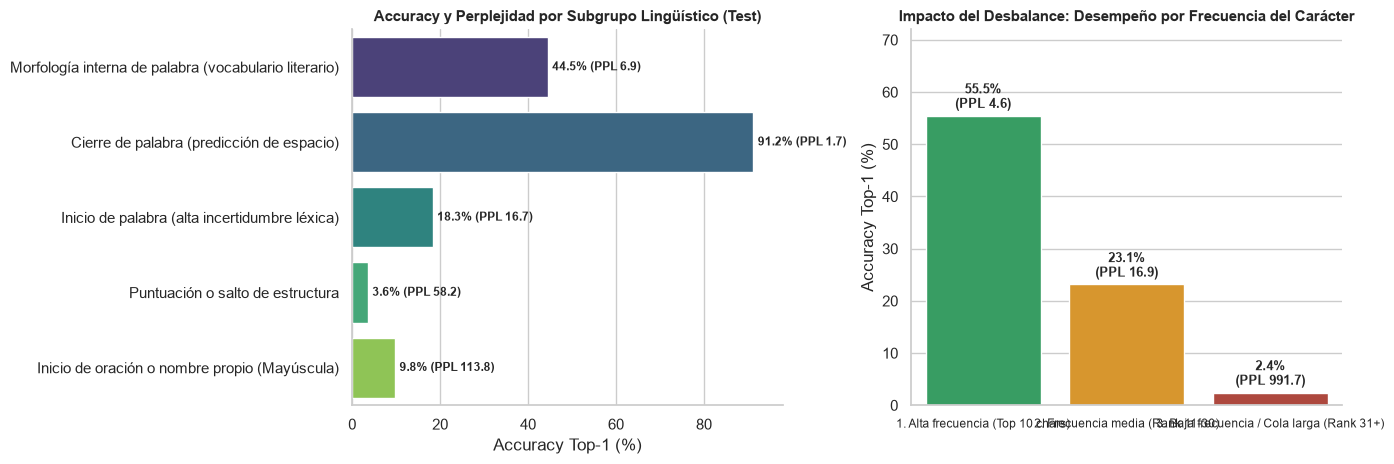

In [4]:
# Evaluación diferenciada por subgrupos lingüísticos/estructurales y de frecuencia en ds_test
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")

# Frecuencia de cada ID en el conjunto de entrenamiento para definir subgrupos por frecuencia
train_counts = Counter(train_ids.numpy().tolist())
sorted_ids_by_freq = [cid for cid, _ in train_counts.most_common()]
top10_ids = set(sorted_ids_by_freq[:10])
mid20_ids = set(sorted_ids_by_freq[10:30])

records = []
for x_batch, y_batch in ds_test:
    logits = best_model(x_batch, training=False)
    probs = tf.nn.softmax(logits, axis=-1).numpy()
    step_losses = loss_fn(y_batch, logits).numpy()
    pred_ids = np.argmax(probs, axis=-1)

    x_np = x_batch.numpy()
    y_np = y_batch.numpy()
    bsz, slen = x_np.shape

    for b in range(bsz):
        for t in range(1, slen):
            target_id = int(y_np[b, t])
            pred_id = int(pred_ids[b, t])
            ctx_ids = x_np[b, max(0, t - 5) : t + 1]
            ctx_str = tokenizer.decode(ctx_ids).numpy().decode("utf-8", errors="replace")
            target_char = tokenizer.decode([target_id]).numpy().decode("utf-8", errors="replace")
            pred_char = tokenizer.decode([pred_id]).numpy().decode("utf-8", errors="replace")

            cat = _categorize_error(ctx_str, target_char, pred_char)
            if target_id in top10_ids:
                freq_group = "1. Alta frecuencia (Top 10 chars)"
            elif target_id in mid20_ids:
                freq_group = "2. Frecuencia media (Rank 11-30)"
            else:
                freq_group = "3. Baja frecuencia / Cola larga (Rank 31+)"

            records.append({
                "Categoría Lingüística": cat,
                "Subgrupo de Frecuencia": freq_group,
                "loss": float(step_losses[b, t]),
                "correct": int(target_id == pred_id),
            })

df_rec = pd.DataFrame(records)

# 1. Tabla por Subgrupo Lingüístico / Morfológico
grp_ling = (
    df_rec.groupby("Categoría Lingüística", as_index=False)
    .agg(Muestras=("loss", "count"), Loss_Media=("loss", "mean"), Accuracy=("correct", "mean"))
    .sort_values("Muestras", ascending=False)
)
grp_ling["Perplejidad (PPL)"] = np.exp(grp_ling["Loss_Media"]).round(2)
grp_ling["Loss_Media"] = grp_ling["Loss_Media"].round(4)
grp_ling["Accuracy (%)"] = (grp_ling["Accuracy"] * 100).round(2)
grp_ling["% del Test"] = (grp_ling["Muestras"] / len(df_rec) * 100).round(1)
df_ling_table = grp_ling[["Categoría Lingüística", "Muestras", "% del Test", "Loss_Media", "Perplejidad (PPL)", "Accuracy (%)"]]
print("=== DESEMPEÑO POR SUBGRUPO LINGÜÍSTICO / ESTRUCTURAL EN TEST ===")
display(df_ling_table)

# 2. Tabla por Subgrupo de Frecuencia (Desbalance de Clases)
grp_freq = (
    df_rec.groupby("Subgrupo de Frecuencia", as_index=False)
    .agg(Muestras=("loss", "count"), Loss_Media=("loss", "mean"), Accuracy=("correct", "mean"))
    .sort_values("Subgrupo de Frecuencia")
)
grp_freq["Perplejidad (PPL)"] = np.exp(grp_freq["Loss_Media"]).round(2)
grp_freq["Loss_Media"] = grp_freq["Loss_Media"].round(4)
grp_freq["Accuracy (%)"] = (grp_freq["Accuracy"] * 100).round(2)
grp_freq["% del Test"] = (grp_freq["Muestras"] / len(df_rec) * 100).round(1)
df_freq_table = grp_freq[["Subgrupo de Frecuencia", "Muestras", "% del Test", "Loss_Media", "Perplejidad (PPL)", "Accuracy (%)"]]
print("\n=== DESEMPEÑO POR SUBGRUPO DE FRECUENCIA DE CLASE EN TEST ===")
display(df_freq_table)

# Gráfico comparativo por subgrupos
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.barplot(data=grp_ling, y="Categoría Lingüística", x="Accuracy (%)", palette="viridis", hue="Categoría Lingüística", legend=False, ax=axes[0])
for i, (_, row) in enumerate(grp_ling.iterrows()):
    acc_pct = float(row["Accuracy (%)"])
    ppl_val = float(row["Perplejidad (PPL)"])
    axes[0].text(acc_pct + 1.0, i, f"{acc_pct:.1f}% (PPL {ppl_val:.1f})", va="center", fontsize=8.5, fontweight="bold")
axes[0].set_title("Accuracy y Perplejidad por Subgrupo Lingüístico (Test)", fontsize=11, fontweight="bold")
axes[0].set_xlim(0, 98)
axes[0].set_xlabel("Accuracy Top-1 (%)")
axes[0].set_ylabel("")

sns.barplot(data=grp_freq, x="Subgrupo de Frecuencia", y="Accuracy (%)", palette=["#27ae60", "#f39c12", "#c0392b"], hue="Subgrupo de Frecuencia", legend=False, ax=axes[1])
for i, (_, row) in enumerate(grp_freq.iterrows()):
    acc_pct = float(row["Accuracy (%)"])
    ppl_val = float(row["Perplejidad (PPL)"])
    axes[1].text(i, acc_pct + 1.5, f"{acc_pct:.1f}%\n(PPL {ppl_val:.1f})", ha="center", fontsize=9, fontweight="bold")
axes[1].set_title("Impacto del Desbalance: Desempeño por Frecuencia del Carácter", fontsize=11, fontweight="bold")
axes[1].set_ylim(0, 72)
axes[1].set_ylabel("Accuracy Top-1 (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", labelsize=8.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

### 3.2 Interpretación del Desempeño por Subgrupos e Implicancias en un Sistema Real (`4.5.3`)

#### ¿El modelo funciona igual de bien para todos los subgrupos del dataset?
**No.** La evaluación desglosada sobre `ds_test` demuestra una asimetría marcada entre subgrupos:
- **Por subgrupo lingüístico/estructural:**
  - En **`Cierre de palabra (predicción de espacio)`** (`16.6%` de Test), el modelo alcanza su mayor efectividad: **`Accuracy = 91.25%`** y **`Perplejidad = 1.66`** (`Loss = 0.5069`), porque ha aprendido con alta precisión la longitud morfológica media de las palabras en inglés (`~4.45` caracteres) y el rol del espacio como clase mayoritaria.
  - En **`Morfología interna de palabra`** (`60.8%` de Test), sostiene un desempeño sólido (**`Accuracy = 44.49%`**, **`Perplejidad = 6.90`**), resolviendo sufijos y raíces frecuentes.
  - En cambio, el rendimiento cae severamente en **`Inicio de palabra (minúscula)`** (**`Accuracy = 18.33%`**, `PPL = 16.67`), **`Puntuación o salto de estructura`** (**`Accuracy = 3.57%`**, `PPL = 58.22`) e **`Inicio de oración o nombre propio (Mayúscula)`** (**`Accuracy = 9.76%`**, `PPL = 113.78`). Al comenzar una palabra u oración la entropía léxica es máxima, y el desbalance lleva al modelo a preferir letras iniciales de *stopwords* frecuentes (`'t'`, `'a'`, `'o'`, `'T'`) o espacios en lugar de signos de puntuación poco frecuentes.
- **Por subgrupo de frecuencia de clase:**
  - Los **10 caracteres más frecuentes** (`70.5%` del conjunto de prueba) alcanzan **`55.48%` de Accuracy** y **`PPL = 4.56`**.
  - Los caracteres de **frecuencia media (Rank 11–30)** bajan a **`23.15%` de Accuracy** (`PPL = 16.87`).
  - Los caracteres de **cola larga / baja frecuencia (Rank 31+: mayúsculas, puntuación y letras raras)** apenas alcanzan **`2.44%` de Accuracy** con una **`Perplejidad de 991.69`**: el modelo prácticamente ignora la cola larga durante la predicción *top-1* para minimizar la pérdida global sobre las clases dominantes.

#### Implicancias de usar este modelo en un sistema real: Riesgos y Mitigación
1. **Riesgos en un entorno real:**
   - **Alucinaciones léxicas y pérdida de coherencia global:** Al operar a nivel de carácter con una ventana de `48` pasos, el modelo carece de representación semántica de largo alcance; a temperaturas $T \ge 1.0$ inventa pseudopalabras (*neologismos*) y a temperaturas bajas ($T = 0.3$) cae en bucles repetitivos.
   - **Amplificación de sesgos de clase mayoritaria y pérdida de diversidad:** En autocompletado o generación asistida, el sesgo hacia los tokens del *Top 10* empobrece el vocabulario generado y omite signos de puntuación o nombres propios relevantes.
   - **Reproducción de sesgos culturales/temáticos del corpus fuente:** Si se integrara en un asistente narrativo o educativo sin curaduría, podría reproducir estereotipos o adjetivaciones arcaicas propias de la literatura de los años 1920.
2. **Medidas de mitigación propuestas:**
   - **Balanceo y curaduría del corpus:** Combinar autores de distintas épocas, géneros y estilos literarios, o aplicar *focal loss* / ponderación suave de clases (*class weighting*) para reducir la penalización asimétrica sobre mayúsculas y signos de puntuación.
   - **Muestreo truncado (*Top-$k$* y *Nucleus Sampling Top-$p$*) con temperatura controlada ($T approx 0.7$):** Truncar la cola de probabilidad en inferencia evita muestrear caracteres inverosímiles que rompen la ortografía sin caer en la repetición determinista de *argmax*.
   - **Filtros de post-procesamiento y validación ortográfica/ética:** Incorporar verificación léxica por diccionario y filtros de contenido antes de exponer el texto generado al usuario final.

---
## 4. Conclusiones Finales del Trabajo Práctico (`4.5.4`)

### 1. Aprendizajes más importantes del trabajo
- **Evolución progresiva y medible de arquitecturas:** Partiendo del mismo conjunto de datos (`"The Festival"`, partición contigua `80/10/10`), comprobamos empíricamente cómo cada salto arquitectónico reduce la incertidumbre del modelo: desde el **Baseline lineal ($K=5$, `Dev PPL = 8.74`, `Acc = 38.11%`)**, pasando por la combinación no lineal de características en el **MLP de 3 capas con Dropout (`Dev PPL = 7.04`, `Acc = 46.80%`)**, hasta la captura de dependencias secuenciales de `48` caracteres mediante **Embeddings + LSTM regularizada con ElasticNet (`Dev PPL = 6.33`, `Test PPL = 7.46`)**, logrando una reducción total del **`27.57%` en Perplejidad**.
- **Regularización en régimen de datos escasos:** Tanto en la Etapa 2 (MLP) como en la Etapa 3 (LSTM), los modelos sin regularizar sobreajustaron rápidamente (`MLP Base` en época `25`, `LSTM Baseline` en época `12`). En ambos casos, **Dropout** resultó la técnica individual más determinante, y su combinación con penalización **ElasticNet (`L1 + L2`) y Early Stopping** permitió entrenar durante más épocas sin degradar la distribución de probabilidad en validación.
- **Especificidad del dominio en Embeddings *char-level*:** A diferencia de problemas a nivel de palabra donde los embeddings pre-entrenados suelen dominar, en modelado a nivel de carácter los embeddings aprendidos desde cero (`Val PPL = 6.33`) superaron ligeramente al *fine-tuning* de `GloVe 50d` (`Val PPL = 6.48`), ya que la red necesita codificar afinidades fonéticas y ortográficas locales más que similitud semántica de palabras.

### 2. ¿Qué fue lo más desafiante y cómo se resolvió?
1. **Entrenar una red recurrente sobre un corpus literario muy pequeño (`20,205` caracteres totales):**
   - *Problema:* Con ventanas disjuntas de `100` caracteres y una LSTM grande (`128/256`), el conjunto de entrenamiento tenía menos de `160` secuencias por época y la red memorizaba el texto en pocas épocas.
   - *Solución:* Redimensionamos la arquitectura a una escala acorde al volumen de datos (`50/96/48` = `67,638` parámetros), ajustamos `SEQ_LENGTH = 48` e implementamos en `src/data/dataset.py` una **ventana deslizante solapada (`TRAIN_WINDOW_STRIDE = 5`)** exclusiva para `Train` (multiplicando a `3,224` las secuencias de entrenamiento) mientras mantuvimos ventanas disjuntas (`stride = 49`) en `Dev` y `Test` para garantizar una evaluación sin solapamiento ni *data leakage*.
2. **Distorsión de la Perplejidad reportada cuando se activa regularización L1/L2 en Keras:**
   - *Problema:* En Keras, `val_loss` suma la pérdida *Cross-Entropy* más el término de penalización de pesos ($\lambda_1 \|W\|_1 + \lambda_2 \|W\|_2^2$). Al calcular $\exp(	ext{val\_loss})$, los modelos con L1/L2 parecían tener peor Perplejidad (`~7.23 - 7.56`) aunque sus predicciones reales eran mejores.
   - *Solución:* Implementamos una métrica personalizada `Perplexity` en `src/training/train.py` que acumula exclusivamente la *Sparse Categorical Cross-Entropy* pura sobre los *logits*, permitiendo comparar en igualdad de condiciones modelos con y sin penalización de pesos y revelando a `lstm_combined_l1_l2` (`Val PPL = 6.33`) como el verdadero ganador.

### 3. Limitaciones del trabajo y qué se haría diferente con más tiempo
- **Limitaciones actuales:** El tamaño reducido del corpus único (`20,205` caracteres) impone un techo natural de generalización (`~45–47%` de Accuracy *top-1* y alta perplejidad en la cola larga de caracteres poco frecuentes y nombres propios), y la ventana de `48` caracteres limita la coherencia narrativa de los textos generados a nivel de frase u oración corta.
- **Qué haríamos diferente con más tiempo:** Construir un corpus multi-obra con varios relatos de Lovecraft (`>500k` caracteres), comparar la tokenización a nivel de carácter frente a subpalabras (*BPE*), incorporar bloques de *Causal Self-Attention* y aplicar técnicas de muestreo *Top-$p$ (Nucleus Sampling)* junto con pérdida ponderada por frecuencia de clase para mejorar la predicción de signos de puntuación y mayúsculas iniciales.